In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.metrics import mean_absolute_error, r2_score

Подключены: pandas и numpy для загрузки и обработки данных, matplotlib и seaborn для визуализации, а из sklearn — инструменты для разделения выборки, масштабирования признаков

## Загрузка и первичный анализ. Предобработка данных

In [2]:
df = pd.read_csv('used_car_price_dataset_extended.csv')

print(f"Размеры таблицы: {df.shape[0]} автомобилей и {df.shape[1]} параметров")

price_by_brand = df.groupby("brand")["price_usd"].median().sort_values(ascending=False)
price_by_fuel = df.groupby("fuel_type")["price_usd"].median().sort_values(ascending=False)

print("\nСредняя цена перепродажи ($) в зависимости от бренда авто: \n", price_by_brand)
print("\nСредняя цена перепродажи ($) в зависимости от типа топлива: \n", price_by_fuel)

df.head(3)

Размеры таблицы: 10000 автомобилей и 12 параметров

Средняя цена перепродажи ($) в зависимости от бренда авто: 
 brand
BMW           7154.850
Ford          7054.810
Honda         7051.430
Volkswagen    7015.750
Toyota        6982.410
Nissan        6942.140
Chevrolet     6881.840
Kia           6876.330
Hyundai       6849.340
Tesla         6815.735
Name: price_usd, dtype: float64

Средняя цена перепродажи ($) в зависимости от типа топлива: 
 fuel_type
Electric    9684.73
Diesel      6754.22
Petrol      6673.44
Name: price_usd, dtype: float64


,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,price_usd,brand,transmission,color,service_history,accidents_reported,insurance_valid
0,2001,8.17,4000,Petrol,4,8587.64,Chevrolet,Manual,White,NaN,0,No
1,2014,17.59,1500,Petrol,4,5943.50,Honda,Manual,Black,NaN,0,Yes
2,2023,18.09,2500,Diesel,5,9273.58,BMW,Automatic,Black,Full,1,Yes


Марка машины почти не влияет на её цену, потому что у всех брендов средняя стоимость практически одинаковая. А вот тип топлива имеет значение: электромобили стоят заметно дороже (почти на 3000$), чем обычные бензиновые или дизельные авто.

## Кодирование и масштабирование 

In [3]:
df = pd.get_dummies(df, drop_first=True)

X = df.drop('price_usd', axis=1)
y = df['price_usd']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

number_cols = ['make_year', 'mileage_kmpl', 'owner_count', 'accidents_reported']
scaler = StandardScaler()
X_train[number_cols] = scaler.fit_transform(X_train[number_cols])
X_test[number_cols] = scaler.transform(X_test[number_cols])

X_train.head(3)


,make_year,mileage_kmpl,engine_cc,owner_count,accidents_reported,fuel_type_Electric,fuel_type_Petrol,brand_Chevrolet,brand_Ford,brand_Honda,...,brand_Toyota,brand_Volkswagen,transmission_Manual,color_Blue,color_Gray,color_Red,color_Silver,color_White,service_history_Partial,insurance_valid_Yes
9254,-0.860884,-1.644253,1800,-0.705460,-0.703197,False,False,False,False,False,...,False,False,True,False,False,False,True,False,True,False
1561,-0.622453,-0.368146,1500,-0.000793,-0.703197,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
1670,-0.503238,-1.482746,5000,-0.705460,-0.703197,False,False,False,True,False,...,False,False,True,False,True,False,False,False,False,False


Текстовые признаки перевели в числа (через get_dummies), а цену выделили в целевую переменную y. Данные разделили на обучающую (80%) и тестовую (20%) выборки, а числовые признаки (make_year, mileage_kmpl, owner_count, accidents_reported) отмасштабировали через StandardScaler, чтобы привести их к одному масштабу.

## Поиск оптимального числа соседей

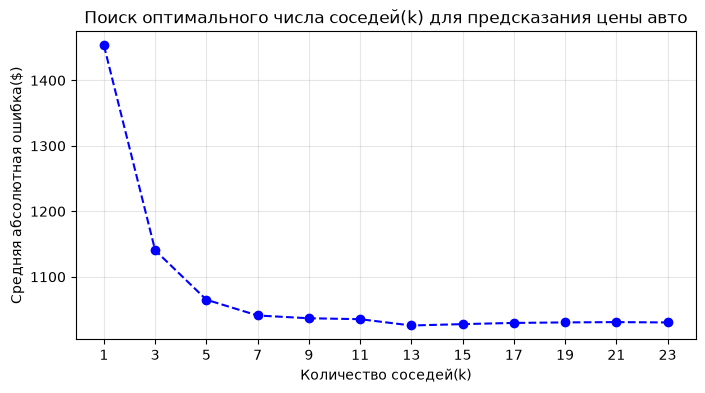

In [4]:
errors = []
k_values = range(1, 25, 2)

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    errors.append(mean_absolute_error(y_test, y_pred))

plt.figure(figsize=(8,4))
plt.plot(k_values, errors, marker="o", linestyle="dashed", color="blue")
plt.title("Поиск оптимального числа соседей(k) для предсказания цены авто")
plt.xlabel("Количество соседей(k)")
plt.ylabel("Средняя абсолютная ошибка($)")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.show()

На графике видно, что при малом количестве соседей (k=1) ошибка очень высокая — около 1450$, но резко падает при увеличении k до 5–7. Начиная с k=7–9 ошибка стабилизируется на уровне примерно 1030–1040$ и почти не меняется при дальнейшем росте k. Поэтому оптимально выбрать k в диапазоне 7–13: модель уже не переобучается, а качество предсказания почти не улучшается при большем числе соседей.

## Исследование метрик расстояния Минковского

In [5]:
best_k = 5

#Обучаем модель с Евклидовой метрикой (р=2)
knn_euclidean = KNeighborsRegressor(n_neighbors=best_k, p=2)
knn_euclidean.fit(X_train, y_train)
y_pred_euc = knn_euclidean.predict(X_test)

#Обучаем модель с Манхэттенской метрикой (р=1)
knn_manhattan = KNeighborsRegressor(n_neighbors=best_k, p=1)
knn_manhattan.fit(X_train, y_train)
y_pred_man = knn_manhattan.predict(X_test)

print("=== Сравнение метрик расстояния ===")
print(f"Евклидово расстояние (p=2): MAE = ${mean_absolute_error(y_test, y_pred_euc):,.2f} | R2 = {r2_score(y_test, y_pred_euc):.2f}")
print(f"Манхэттенское расстояние (p=1): MAE = ${mean_absolute_error(y_test, y_pred_man):,.2f} | R2 = {r2_score(y_test, y_pred_man):.2f}")

=== Сравнение метрик расстояния ===
Евклидово расстояние (p=2): MAE = $1,064.99 | R2 = 0.77
Манхэттенское расстояние (p=1): MAE = $1,095.46 | R2 = 0.76


Евклидово расстояние (p=2) показало чуть лучшие результаты: у него ниже ошибка (MAE) и выше точность (R²), чем у Манхэттенского.

## Регрессия Надарая-Ватсона

In [6]:
gamma_values = np.logspace(-2,1 , 30)

best_gamma = 0
best_r2 = -float("inf")
best_mae = float("inf")

for g in gamma_values:
    weights = rbf_kernel(X_test, X_train, gamma=g)
    weights_normalized = weights/ weights.sum(axis=1, keepdims=True)

    y_pred_nw = np.dot(weights_normalized, y_train.values)

    r2 = r2_score(y_test, y_pred_nw)
    mae = mean_absolute_error(y_test, y_pred_nw)

    if r2 > best_r2:
        best_r2 = r2
        best_mae = mae
        best_gamma = g 

print("=== Итоги оптимизации ядерной регрессии ===")
print(f"Оптимальный gamma: {best_gamma:.2f}")
print(f"Лучшее R2: {best_r2:.2f}")
print(f"Лучшее MAE: ${best_mae:.2f}")

=== Итоги оптимизации ядерной регрессии ===
Оптимальный gamma: 0.92
Лучшее R2: 0.77
Лучшее MAE: $1038.87


Модель показала при параметре gamma = 0.92. Точность предсказания составила 0.77, а средняя ошибка составила 1038.87 долларов.

## Визуализация результатов: Реальная и предсказанная цена автомобиля

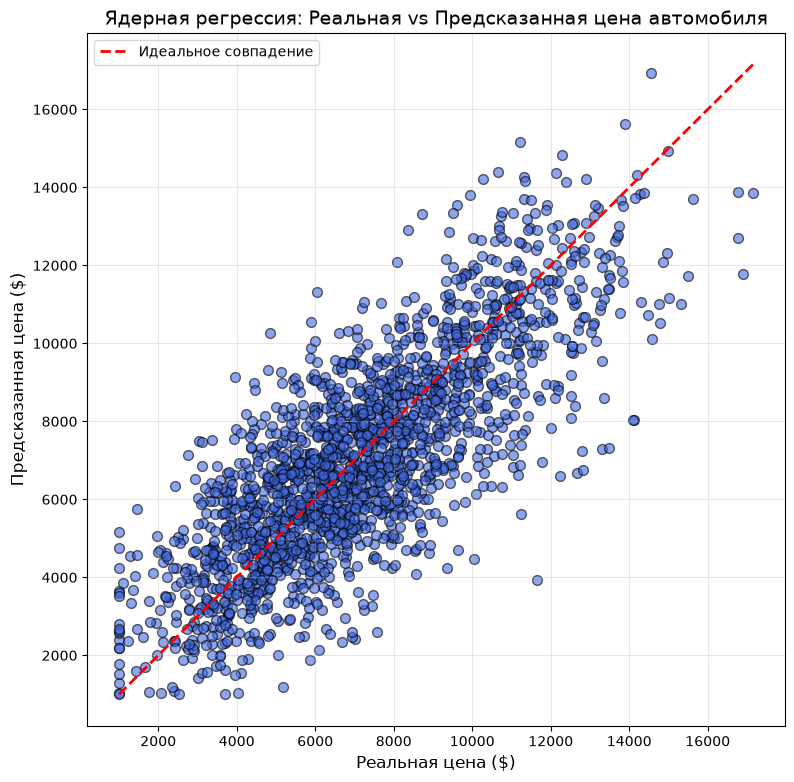

In [7]:
plt.figure(figsize=(9, 9))

plt.scatter(y_test, y_pred_nw, alpha=0.6, color="royalblue", edgecolor="k", s=50)

max_val = max(y_test.max(), y_pred_nw.max())
min_val = min(y_test.min(), y_pred_nw.min())

plt.plot(
    [min_val, max_val], [min_val, max_val], "r--", lw=2, label="Идеальное совпадение"
)

plt.title("Ядерная регрессия: Реальная vs Предсказанная цена автомобиля", fontsize=14)
plt.xlabel("Реальная цена ($)", fontsize=12)
plt.ylabel("Предсказанная цена ($)", fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Модель хорошо предсказывает цену для большинства автомобилей среднего ценового диапазона, так как точки на графике плотно группируются вокруг линии идеального совпадения. Для очень дешевых или дорогих машин ошибка увеличивается из-за нехватки примеров в данных, но в целом результат вполне подходит для быстрой предварительной оценки.